# Лабораторная работа № 4
## CTC с нуля

Цель работы - разобраться, как CTC считает вероятность текста без покадровой разметки, и проверить, почему жадный поиск и префиксный луч могут дать разные расшифровки

## 0. Подготовка

Дополняю шесть функций в исходных скриптах из задания.\
Для алгоритмов достаточно стандартной библиотеки Python

| Набор | Что проверяю |
|---|---|
| [forward.json](data/forward.json) | Вероятность `ba` через перебор и прямой проход |
| [repeated.json](data/repeated.json) | Сколько кадров нужно для двух одинаковых букв в `bb` |
| [decoding.json](data/decoding.json) | Результат жадного поиска и префиксного луча |

В JSON записаны синтетические покадровые вероятности. Путь содержит один токен на кадр, а после свёртки строка может быть короче. Служебный токен `blank` убирается из текста и может разделять две одинаковые буквы

In [1]:
from collections import defaultdict
import csv
from html import escape
import json
import math
from pathlib import Path
import subprocess
import sys

from IPython.display import HTML, SVG, display
import matplotlib.pyplot as plt

%matplotlib inline

ROOT = Path.cwd()
if not (ROOT / "scripts" / "run_lab_04.py").is_file():
    raise FileNotFoundError("Запустите ноутбук из корня lab_04_ru")

from scripts.ctc_core import collapse_path, enumerate_paths, sum_transcript_probability
from scripts.ctc_decode import greedy_decode, prefix_beam_decode
from scripts.ctc_forward import extended_target, forward_table, transcript_probability

DATA = ROOT / "data"
OUT = ROOT / "outputs"

fixtures = {}
for name in ("forward", "repeated", "decoding"):
    fixtures[name] = json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))


def show_table(headers, rows):
    header = "".join(f"<th>{escape(str(value))}</th>" for value in headers)
    body = []
    for row in rows:
        row_html = "".join(f"<td>{escape(str(value))}</td>" for value in row)
        body.append(f"<tr>{row_html}</tr>")
    display(HTML(f"<table><thead><tr>{header}</tr></thead><tbody>{''.join(body)}</tbody></table>"))

## 1. Часть A. Свёртка и перебор путей

В ctc_core.py функция `merge_then_remove` сравнивает очередной токен с предыдущим в исходном пути. Поэтому `b b` даёт `b`, а `b blank b` даёт `bb`. Функция `sum_matching` складывает вероятности тех путей, у которых после свёртки вышла заданная строка

В `forward.json` три кадра и три возможных токена на каждом кадре, значит, всего $3^3=27$ путей. Посмотрю на вероятности в исходном наборе и выведу все пути, которые дают `ba`. Вероятность каждого пути получаю умножением вероятностей выбранных токенов по кадрам

In [2]:
forward = fixtures["forward"]
alphabet = forward["alphabet"]
emissions = forward["emissions"]
target = forward["target"]
blank = forward["blank"]

emission_rows = [
    [frame] + [f"{row[symbol]:.2f}" for symbol in alphabet]
    for frame, row in enumerate(emissions, start=1)
]
show_table(["Кадр", *alphabet], emission_rows)

records = enumerate_paths(emissions, alphabet, blank)
matches = [record for record in records if record["transcript"] == target]
p_target = sum_transcript_probability(records, target)

path_rows = []
for record in matches:
    path = record["path"]
    factors = " × ".join(f"{row[token]:.2f}" for row, token in zip(emissions, path))
    path_rows.append((" ".join(path), factors, f"{record['probability']:.3f}"))

show_table(
    ["Путь", "Произведение", "Вероятность"],
    path_rows + [("Сумма", "", f"{p_target:.3f}")],
)
print(f"Из {len(records)} путей в {target} сворачиваются {len(matches)}")
print(f"CTC-loss для {target} = {-math.log(p_target):.6f}")

assert len(records) == 27 and len(matches) == 5
assert math.isclose(sum(record["probability"] for record in records), 1)
assert math.isclose(p_target, 0.661)

Кадр,blank,b,a
1,0.10,0.80,0.10
2,0.20,0.30,0.50
3,0.20,0.10,0.70


Путь,Произведение,Вероятность
blank b a,0.10 × 0.30 × 0.70,0.021
b blank a,0.80 × 0.20 × 0.70,0.112
b b a,0.80 × 0.30 × 0.70,0.168
b a blank,0.80 × 0.50 × 0.20,0.080
b a a,0.80 × 0.50 × 0.70,0.280
Сумма,,0.661


Из 27 путей в ba сворачиваются 5
CTC-loss для ba = 0.414001


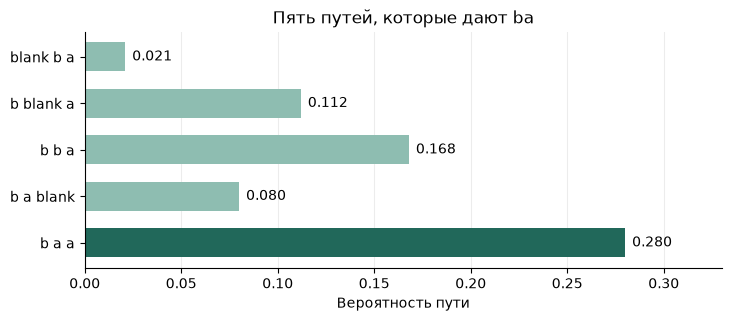

In [3]:
paths = [" ".join(record["path"]) for record in matches]
probabilities = [record["probability"] for record in matches]
best_path_index = probabilities.index(max(probabilities))
colors = ["#21685a" if i == best_path_index else "#8ebdb1" for i in range(len(paths))]

fig, ax = plt.subplots(figsize=(7.2, 3.1), layout="constrained")
bars = ax.barh(paths, probabilities, color=colors, height=0.62)
ax.bar_label(bars, fmt="%.3f", padding=5)
ax.invert_yaxis()
ax.set(xlim=(0, 0.33), xlabel="Вероятность пути", title="Пять путей, которые дают ba")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.24)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Вывод по перебору**

Самый вероятный путь `b a a` даёт 0.280. Остальные четыре пути вместе дают ещё 0.381, поэтому для текста `ba` получаю 0.661. CTC-loss для одного примера равен отрицательному натуральному логарифму этой суммы, то есть $-\ln(0.661) \approx 0.414001$

## 2. Часть B. Прямой проход

Расширенная цель для `ba` - `[blank, b, blank, a, blank]`. Нумерую состояния с нуля, а кадры с единицы. Ячейка $\alpha_{t,s}$ хранит сумму вероятностей частичных путей, пришедших на кадре $t$ в состояние $s$. На первом кадре можно начать с начального `blank` или с `b`

В ctc_forward.py функция `incoming_sum` складывает вклады с прошлого кадра. Можно остаться в $s$, перейти из $s-1$ или пропустить промежуточное состояние и перейти из $s-2$. Пропуск разрешён, если индекс существует, токен в $s$ отличается от `blank` и от токена в $s-2$. Затем `forward_table` умножает сумму на вероятность текущего токена

In [4]:
states = extended_target(target, blank)
alpha = forward_table(emissions, target, blank)
alpha_rows = [
    [frame] + [f"{value:.3f}" for value in row]
    for frame, row in enumerate(alpha, start=1)
]
show_table(["Кадр"] + [f"{i}: {token}" for i, token in enumerate(states)], alpha_rows)

p_forward = transcript_probability(alpha)
print(f"Терминальные ячейки {alpha[-1][-2]:.3f} и {alpha[-1][-1]:.3f}")
print(f"Вероятность {target} по прямому проходу = {p_forward:.3f}")
assert math.isclose(p_forward, p_target)

Кадр,0: blank,1: b,2: blank,3: a,4: blank
1,0.100,0.800,0.000,0.000,0.000
2,0.020,0.270,0.160,0.400,0.000
3,0.004,0.029,0.086,0.581,0.080


Терминальные ячейки 0.581 и 0.080
Вероятность ba по прямому проходу = 0.661


### Ручная проверка терминальных ячеек

Для `a` на третьем кадре есть три входа со второго кадра. Это `a`, промежуточный `blank` и `b`. Для последнего `blank` доступны только сохранение состояния и переход из `a`

$$\alpha_{3,3} = 0.7(0.400 + 0.160 + 0.270) = 0.581$$

$$\alpha_{3,4} = 0.2(0.000 + 0.400) = 0.080$$

`terminal_sum` складывает последние две ячейки, потому что полный текст `ba` можно закончить на `a` или на следующем `blank`. Для пустой цели есть только одно состояние с `blank`. Сумма 0.661 совпала с полным перебором

### Проверка на `bb`

Между двумя `b` в расширенной цели `[blank, b, blank, b, blank]` пропуск запрещён. Без промежуточного `blank` две соседние буквы слились бы в одну. Сравню результат на всех трёх кадрах и только на первых двух

In [ ]:
repeated = fixtures["repeated"]
repeated_rows = []
for frame_count in (2, 3):
    rows = repeated["emissions"][:frame_count]
    table = forward_table(rows, repeated["target"], repeated["blank"])
    paths_with_repeat = enumerate_paths(rows, repeated["alphabet"], repeated["blank"])

    matching = [
        record for record in paths_with_repeat
        if record["transcript"] == repeated["target"]
    ]
    
    p_repeat = transcript_probability(table)
    p_repeat_exact = sum_transcript_probability(paths_with_repeat, repeated["target"])

    assert math.isclose(p_repeat, p_repeat_exact)
    repeated_rows.append((frame_count, len(matching), f"{p_repeat_exact:.3f}", f"{p_repeat:.3f}"))

show_table(["Кадров", "Путей для bb", "Перебор", "Прямой проход"], repeated_rows)

Кадров,Путей для bb,Перебор,Прямой проход
2,0,0.000,0.000
3,1,0.125,0.125


На двух кадрах `bb` получить невозможно. На трёх подходит ровно один путь `b blank b`. Вероятность каждого токена в нём равна 0.5, поэтому оба расчёта дали $0.5^3=0.125$

## 3. Часть C. Жадный поиск и префиксный луч

В ctc_decode.py функция `greedy_path` берёт токен с максимальной вероятностью на каждом кадре. При равенстве `max` сохраняет первый токен по порядку в алфавите. После выбора всех токенов путь сворачивается

Луч хранит для каждого частичного текста две суммы, по путям с последним `blank` и с последней буквой. В `prefix_transitions` повтор буквы продлевает текст, если предыдущий токен был `blank`. Иначе буква сливается с предыдущей и текст не меняется. Например, `a blank a` даёт `aa`, а `a a` даёт `a`. При добавлении другой буквы обе группы продлевают префикс. На каждом кадре скрипт сначала складывает вклады по одинаковым префиксам, затем оставляет до пяти лучших

In [6]:
decoding = fixtures["decoding"]
decode_rows = decoding["emissions"]
decode_alphabet = decoding["alphabet"]
decode_blank = decoding["blank"]
beam_width = decoding["beam_width"]

greedy_path, greedy_text = greedy_decode(decode_rows, decode_alphabet, decode_blank)
greedy_mass = math.prod(row[token] for row, token in zip(decode_rows, greedy_path))
winner, beam = prefix_beam_decode(decode_rows, decode_alphabet, beam_width, decode_blank)

show_table(
    ["Кадр", *decode_alphabet, "Выбранный токен"],
    [
        [frame] + [f"{row[token]:.2f}" for token in decode_alphabet] + [selected]
        for frame, (row, selected) in enumerate(zip(decode_rows, greedy_path), start=1)
    ],
)
print(f"Жадный путь {' '.join(greedy_path)} → {greedy_text}, вероятность пути {greedy_mass:.4f}")

# Сверяю массу луча с полным перебором на том же наборе
decode_records = enumerate_paths(decode_rows, decode_alphabet, decode_blank)
exact_mass = defaultdict(float)
for record in decode_records:
    exact_mass[record["transcript"]] += record["probability"]

show_table(
    ["Место", "Текст", f"Масса в луче ширины {beam_width}", "Полный перебор"],
    [
        (place, prefix, f"{mass:.4f}", f"{exact_mass[prefix]:.4f}")
        for place, (prefix, mass) in enumerate(beam, start=1)
    ],
)
assert (greedy_text, winner) == ("a", "ab")
assert all(math.isclose(mass, exact_mass[prefix]) for prefix, mass in beam)

Кадр,blank,a,b,Выбранный токен
1,0.10,0.60,0.30,a
2,0.45,0.20,0.35,blank
3,0.45,0.20,0.35,blank


Жадный путь a blank blank → a, вероятность пути 0.1215


Место,Текст,Масса в луче ширины 5,Полный перебор
1,ab,0.3115,0.3115
2,a,0.2215,0.2215
3,b,0.1885,0.1885
4,ba,0.0940,0.0940
5,aa,0.0540,0.0540


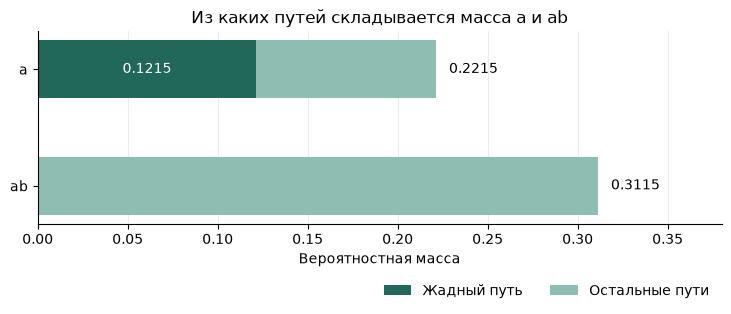

In [ ]:
labels = [greedy_text, winner]
greedy_part = [greedy_mass, 0]
other_paths = [exact_mass[text] - part for text, part in zip(labels, greedy_part)]

fig, ax = plt.subplots(figsize=(7.2, 3), layout="constrained")
ax.barh(labels, greedy_part, color="#21685a", height=0.5, label="Жадный путь")
ax.barh(labels, other_paths, left=greedy_part, color="#8ebdb1", height=0.5, label="Остальные пути")

for text in labels:
    ax.text(exact_mass[text] + 0.007, text, f"{exact_mass[text]:.4f}", va="center")

ax.text(greedy_mass / 2, greedy_text, f"{greedy_mass:.4f}", color="white", ha="center", va="center")
ax.invert_yaxis()
ax.set(xlim=(0, 0.38), xlabel="Вероятностная масса", title="Из каких путей складывается масса a и ab")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.24)
ax.legend(loc="upper right", bbox_to_anchor=(1, -0.25), ncol=2, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

**Вывод по декодированию**

`a blank blank` - самый вероятный отдельный путь с вероятностью $0.60\cdot0.45\cdot0.45=0.1215$. Для текста `a` к нему добавляются ещё пять путей, полная масса получается 0.2215

Текст `ab` дают пять путей: `blank a b`, `a blank b`, `a a b`, `a b blank` и `a b b`. Самый вероятный из них даёт 0.0945, а вместе они дают $0.007+0.0945+0.042+0.0945+0.0735=0.3115$. Поэтому при сравнении отдельных путей выигрывает путь для `a`, а при сравнении сумм первым становится `ab`

### Что меняется с шириной луча

На первых двух кадрах набора есть 3 и 5 возможных текстов соответственно, включая пустую строку. При ширине 5 все они доживают до третьего кадра, поэтому массы итоговых пяти строк совпали с перебором. Сравню это с меньшей шириной

In [8]:
width_rows = []
for width in (1, 2, 3, 5):
    best, ledger = prefix_beam_decode(decode_rows, decode_alphabet, width, decode_blank)
    width_rows.append((width, best, f"{ledger[0][1]:.4f}", f"{exact_mass[best]:.4f}"))

show_table(["Ширина", "Лучший текст", "Масса в луче", "Точная масса этого текста"], width_rows)

Ширина,Лучший текст,Масса в луче,Точная масса этого текста
1,a,0.1995,0.2215
2,a,0.1995,0.2215
3,ab,0.3115,0.3115
5,ab,0.3115,0.3115


При ширине 1 префикс `ab` отсекается уже на втором кадре, а на последнем побеждает `a`. Его масса 0.1995 меньше точного значения 0.2215, потому что часть путей к `a` тоже потеряна при отсечении

## 4. Запуск исходного скрипта и проверка

Запускаю `run_lab_04.py` из корня проекта.\
Сверю сохранённую таблицу со значениями прямого прохода и выведу SVG из `outputs/`.\
В SVG цветом выделены две терминальные ячейки

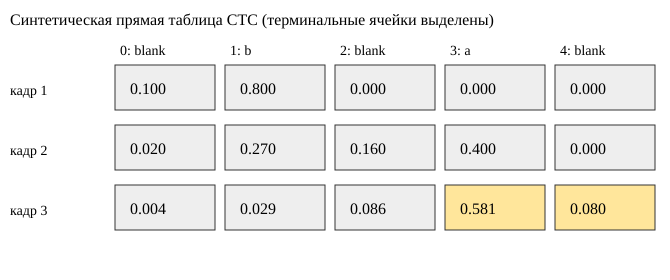

In [9]:
subprocess.run(
    [sys.executable, "-B", str(ROOT / "scripts" / "run_lab_04.py"), "--output-dir", str(OUT)],
    cwd=ROOT,
    check=True,
)

with (OUT / "forward_table.csv").open(encoding="utf-8", newline="") as file:
    csv_reader = csv.reader(file)
    next(csv_reader)
    saved_alpha = [[float(value) for value in row[1:]] for row in csv_reader]

summary = json.loads((OUT / "summary.json").read_text(encoding="utf-8"))
assert saved_alpha == alpha
assert math.isclose(summary["transcript_probability"], p_forward)
assert (summary["greedy_transcript"], summary["beam_best"]) == (greedy_text, winner)

display(SVG(filename=str(OUT / "forward_table.svg")))

В `outputs/` сохранились [27 путей](outputs/paths.csv), [таблица alpha](outputs/forward_table.csv), [результаты декодирования](outputs/decoding.csv), [сводка](outputs/summary.json) и [таблица alpha в SVG](outputs/forward_table.svg)

Дополнительно проверяю свёртку с `blank`, правило выбора при равных эмиссиях и штатные тесты проекта

In [10]:
assert collapse_path(["b", "b"]) == "b"
assert collapse_path(["b", "blank", "b"]) == "bb"
tied_rows = [{"blank": 0.5, "a": 0.5}]
assert greedy_decode(tied_rows, ["blank", "a"])[0] == ["blank"]
assert greedy_decode(tied_rows, ["a", "blank"])[0] == ["a"]

tests = subprocess.run(
    [sys.executable, "-X", "utf8", "-B", "-m", "unittest", "discover", "-s", "tests", "-v"],
    cwd=ROOT,
    capture_output=True,
    encoding="utf-8",
)
print(tests.stderr.strip())
tests.check_returncode()

test_collapse (test_ctc_core.CoreTests.test_collapse) ... ok
test_invalid (test_ctc_core.CoreTests.test_invalid) ... ok
test_paths (test_ctc_core.CoreTests.test_paths) ... ok
test_zero_and_invalid_values (test_ctc_core.CoreTests.test_zero_and_invalid_values) ... ok
test_accumulate_then_prune_each_frame (test_ctc_decode.DecodeTests.test_accumulate_then_prune_each_frame) ... ok
test_edges (test_ctc_decode.DecodeTests.test_edges) ... ok
test_fixed (test_ctc_decode.DecodeTests.test_fixed) ... ok
test_zero_and_ties (test_ctc_decode.DecodeTests.test_zero_and_ties) ... ok
test_forward_table (test_ctc_forward.ForwardTests.test_forward_table) ... ok
test_repeat_empty_and_errors (test_ctc_forward.ForwardTests.test_repeat_empty_and_errors) ... ok
test_outputs_and_cwd (test_lab_04_runner.RunnerTests.test_outputs_and_cwd) ... ok

----------------------------------------------------------------------
Ran 11 tests in 0.375s

OK


## 5. Ответы на вопросы

### 1. Сколько путей дают `ba` и чему равны терминальные ячейки?

Из 27 путей в `ba` сворачиваются 5. Их суммарная вероятность равна 0.661. На третьем кадре $\alpha_{3,3}=0.581$ соответствует завершению на `a`, а $\alpha_{3,4}=0.080$ - завершению на `blank`

### 2. Что выдали жадный поиск и луч ширины 5?

Жадный поиск выбрал `a blank blank` с вероятностью 0.1215 и свернул его в `a`. Луч ширины 5 вернул `ab` с массой 0.3115. Вероятность пути относится к одной последовательности покадровых токенов. Масса текста суммирует вероятности всех путей, которые сворачиваются в эту строку. Например, точная масса `a` равна 0.2215

### 3. Какие ограничения есть у примера и как его развить?

Три синтетических кадра позволяют сверить результат с перебором. Для оценки качества ASR нужны эмиссии обученной CTC-модели на реальных записях и эталонные тексты. На таких данных можно сравнить символьную и словную частоту ошибок (CER и WER) при разной ширине луча

При малой ширине часть префиксов отсекается, поэтому может измениться и оценка, и итоговый текст. В нашем примере при ширине 1 побеждает `a` с массой 0.1995, а при ширине 5 побеждает `ab` с массой 0.3115

На длинных записях произведения малых вероятностей могут округлиться до нуля. В прямом проходе и луче можно хранить логарифмы вероятностей, складывать их вдоль пути и объединять альтернативные пути через `logsumexp`